# 概要 overview

作成したモデルに対してSHAP分析を行い、
強度に影響を及ぼす因子に関して確認する

## ライブラリ読み込み

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import joblib
from sklearn.model_selection import train_test_split

import shap

RANDOM_STATE=42

## データの読み込み

データの読み込み
PandasDataFrameで渡したいので、関数使わず読み込み。
（nparrayはSHAP分析で項目名が出てこない）

In [38]:
data_path =  "data/Concrete_Data.xlsx"

df = pd.read_excel(data_path)

# 項目名簡略化のため、()内の記述削除
df.columns = df.columns.str.replace(r"\s*\([^)]*\)", "", regex=True)


X = df.drop(columns=["Concrete compressive strength "])
Y = df["Concrete compressive strength "]

# 訓練データと検証データに分割（8:2）
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)


## モデルの読み込み

学習済みモデルを読み込む。
今回は、LightGBMモデル

In [39]:
# モデルの読み込み
saved_data = joblib.load("results/GBDT/GBDT_model.pkl")

# 注：辞書型になっている。"model"キーにmodelが入っている。
print(saved_data.keys())

# 辞書の中からモデル本体を取り出す
model = saved_data["model"]

dict_keys(['model', 'input_dim', 'output_dim'])


## SHAP分析

モデル学習に使ったtrainデータと、テストデータそれぞれ分析に掛ける

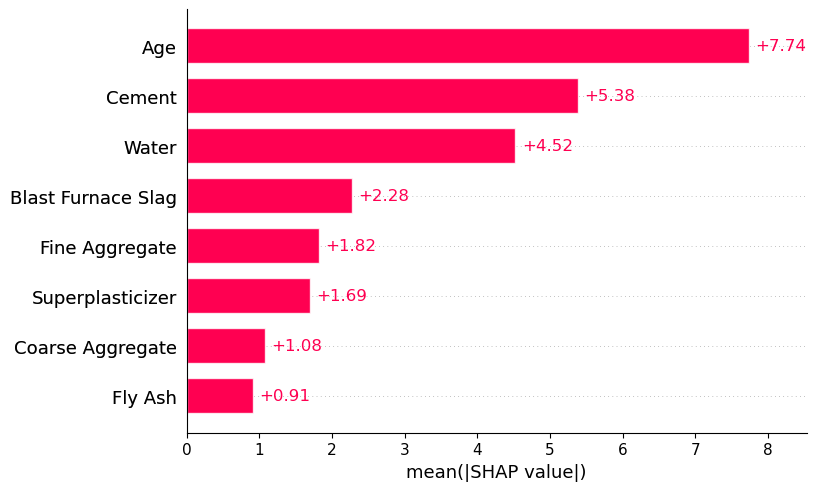

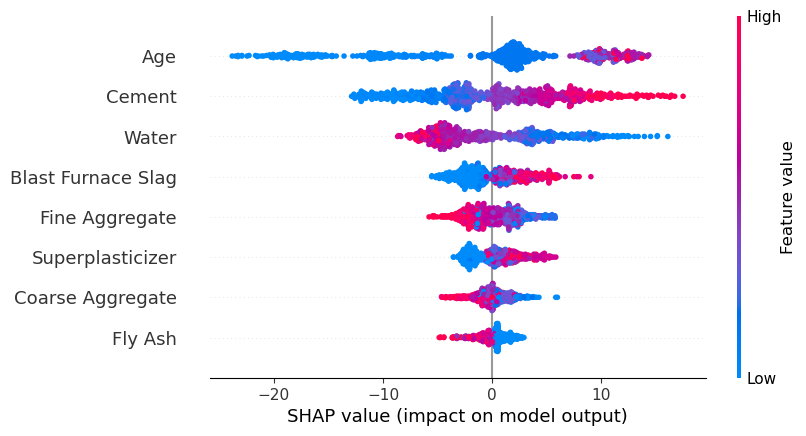

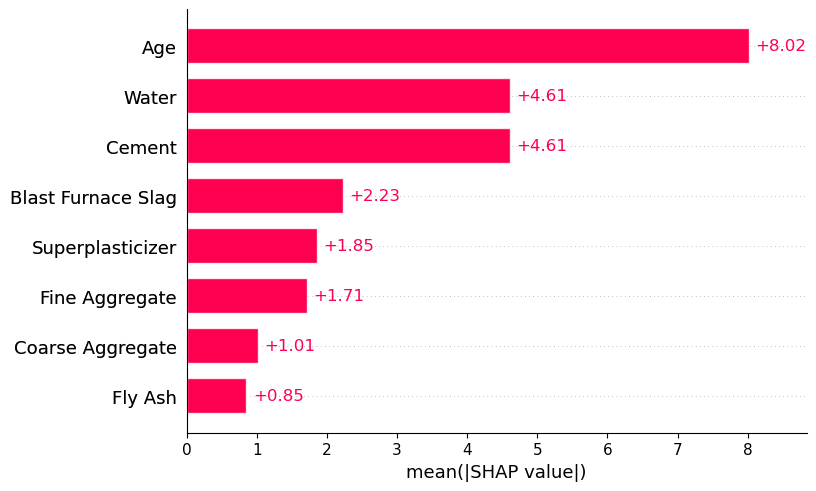

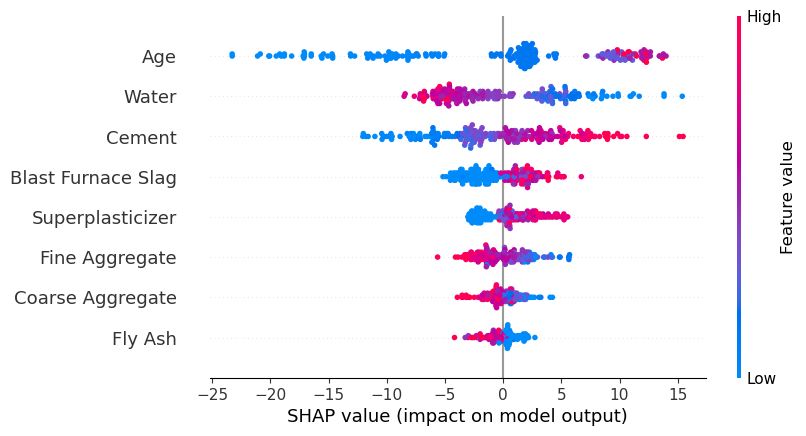

In [40]:

# TreeExplainer を作成（LGBMRegressor / RandomForestRegressor どちらでも利用可能）
explainer = shap.TreeExplainer(model)
shap_exp_train = explainer(X_train)
shap_exp_test = explainer(X_test)

# 1) Bar plot（全体ランキング）
shap.plots.bar(shap_exp_train)

# 2) Beeswarm plot（影響の向きと分布）
shap.plots.beeswarm(shap_exp_train)

# testデータでも同様の傾向を得られているか
shap.plots.bar(shap_exp_test)
shap.plots.beeswarm(shap_exp_test)


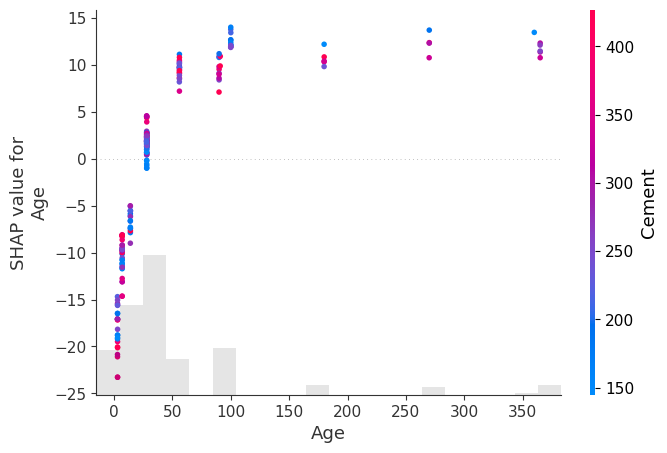

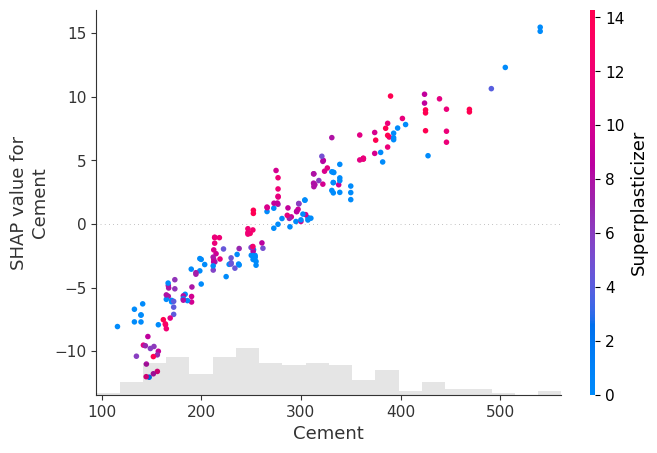

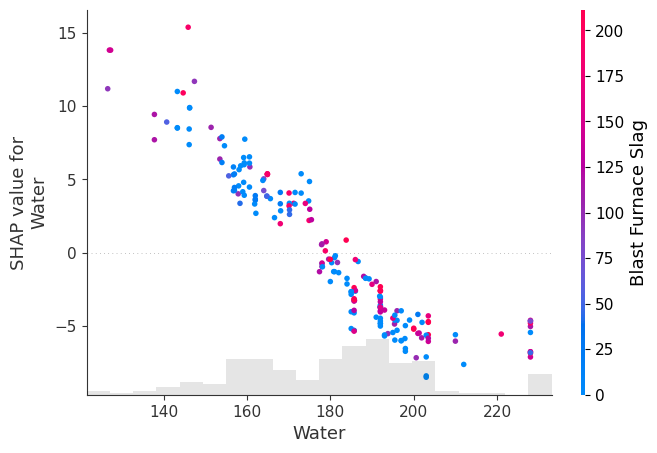

In [41]:

# Dependence plot(scatter)：最上位の特徴量について、相互作用の強い列を自動色分けで表示
# 注:Explanationオブジェクトの場合は"scatter"

feature = "Age"  # 文字列で指定
shap.plots.scatter(shap_exp_test[:, feature], color=shap_exp_test)

feature = "Cement"  # 文字列で指定
shap.plots.scatter(shap_exp_test[:, feature], color=shap_exp_test)

feature = "Water"  # 文字列で指定
shap.plots.scatter(shap_exp_test[:, feature], color=shap_exp_test)

# 分析・考察

bar_plotおよびBeeswarmの図より
上から"Age""Cement""Water"が強度に大きく影響を及ぼしている。
"Age""Cement"⇒増加　"Water"⇒減少
により、強度が高まることが期待できる。

今後のさらなる分析に向けて、
depandanceplotをみると、対数関数のような変化をしている。
　⇒log("Age")により増加曲線を抑制し、細やかな変化をとらえやすい可能性あり

また、dependence_plotより、"Age"と"Cement"の関係が深い
　⇒log("Age")*"Cement"　などの特徴量エンジニアリングが有効な可能あり

同じくdependence_plotより、"Cement"と"Superplasticizer"の関係が深い
　⇒Superplasticizer=減水剤＝添加剤であることから
　　"Superplasticizer"/"Cement"(添加比率)などの特徴量エンジニアリングが有効な可能あり



## 予測を外した個別データの分析

In [ ]:


# 予測値
y_pred = model.predict(X_test)

display(y_pred.shape)

# 実測値と予測値
result_df = pd.DataFrame({
    "Actual": Y_test.to_numpy().flatten(),
    "Predicted": y_pred.flatten(),
})

# 誤差
result_df["Error"] = result_df["Predicted"] - result_df["Actual"]
result_df["Abs_Error"] = result_df["Error"].abs()

# 絶対誤差の大きい順に並べる
result_df = result_df.sort_values(
    "Abs_Error", ascending=False
)

# 誤差上位10件を抽出
display(result_df.head(10))

(206,)

,Actual,Predicted,Error,Abs_Error
54,64.017847,46.820421,-17.197426,17.197426
109,44.519465,61.436839,16.917374,16.917374
182,44.523602,61.436839,16.913237,16.913237
158,55.895819,42.058146,-13.837673,13.837673
1,55.895819,42.058146,-13.837673,13.837673
119,53.524022,39.768969,-13.755053,13.755053
94,53.524711,39.987085,-13.537626,13.537626
33,66.424118,53.882471,-12.541646,12.541646
196,60.322255,50.073984,-10.248271,10.248271
10,25.096926,34.951128,9.854202,9.854202


[54, 109, 182, 158, 1]


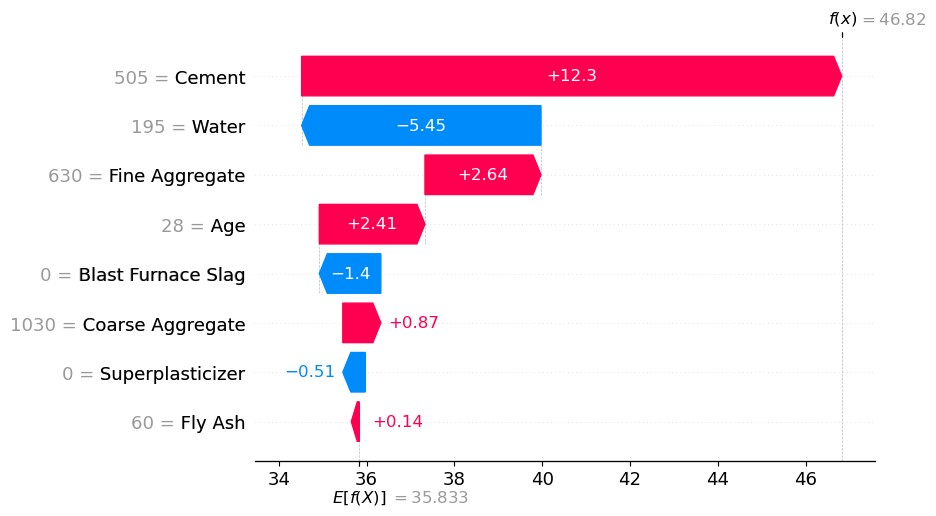

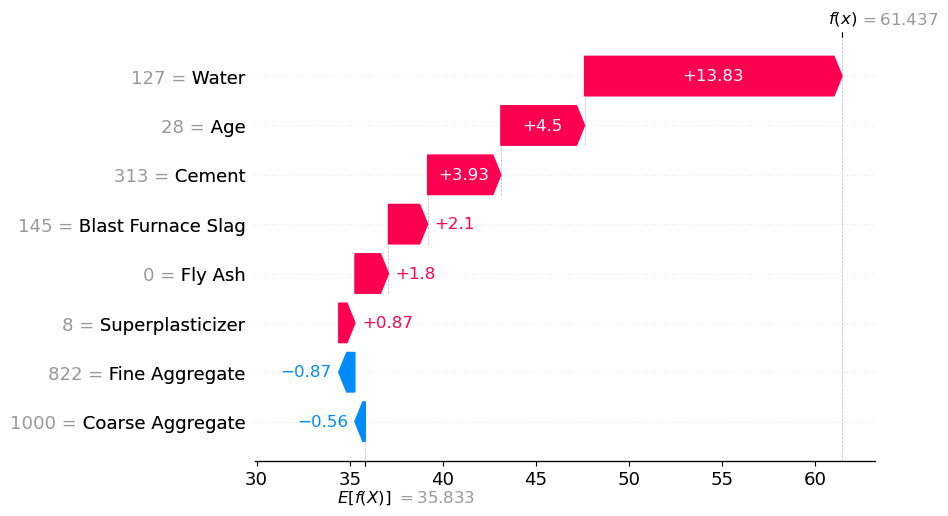

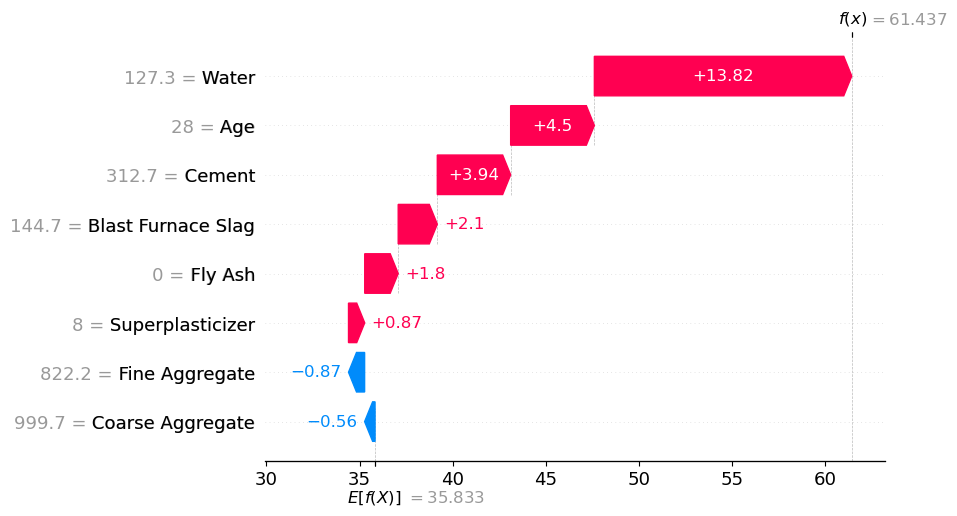

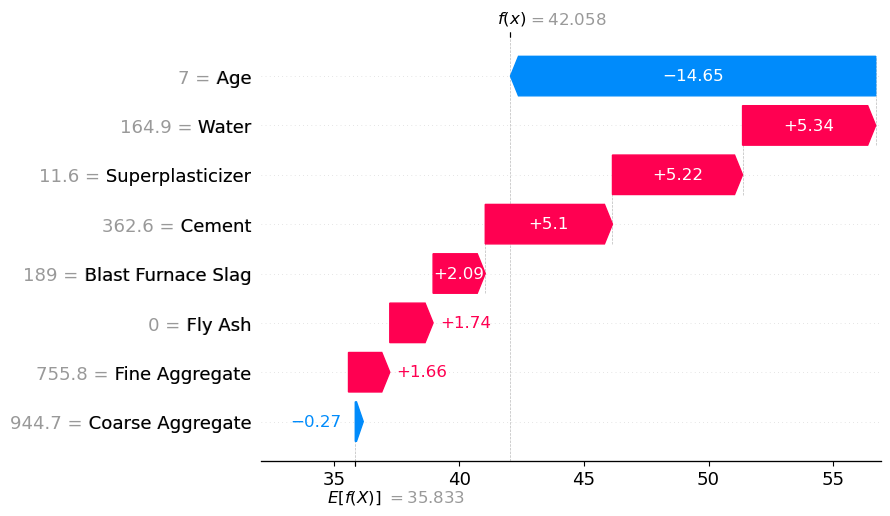

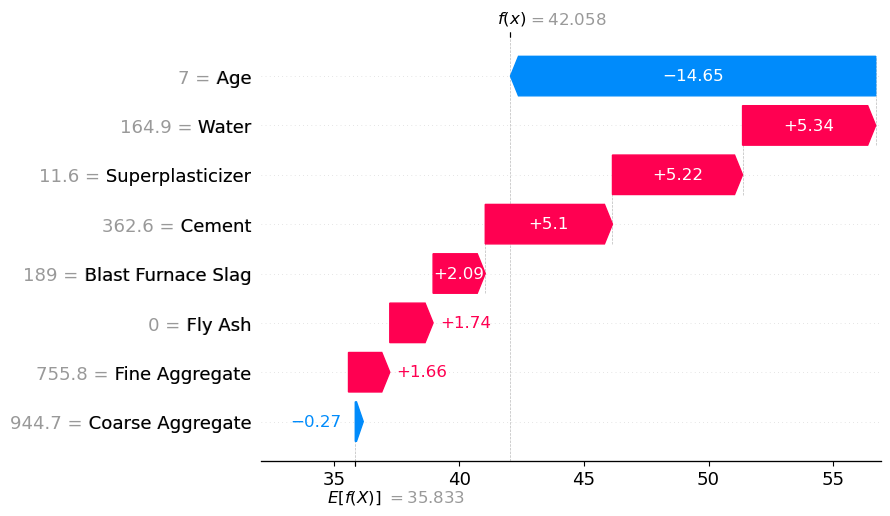

In [51]:
# # 誤差最大のサンプルのインデックス
# worst_idx = result_df["Abs_Error"].idxmax()

# 誤差が大きい上位3つのインデックスを取得
worst_idx = result_df["Abs_Error"].nlargest(5).index.tolist()

print(worst_idx)

for i in worst_idx:
    # 対応するSHAP値を表示
    shap.plots.waterfall(shap_exp_test[i])

Cement=505もWater=127もデータの最大値、最小値付近
データ不足による誤差と推定

データ分布確認

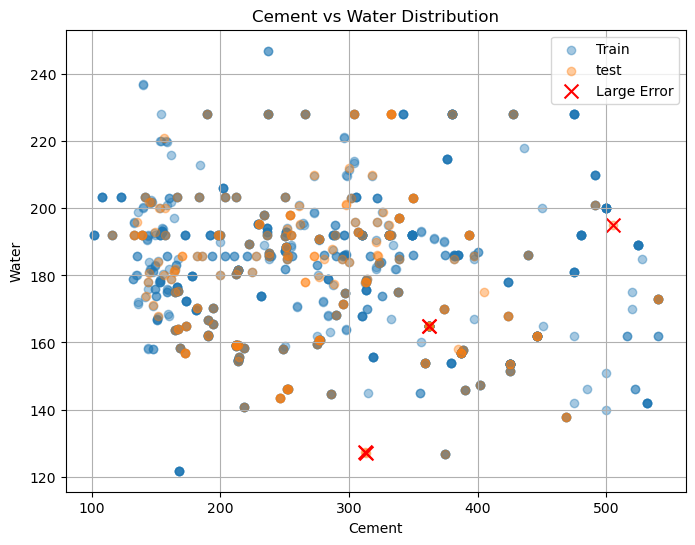

In [53]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train["Cement"],
    X_train["Water"],
    alpha=0.4,
    label="Train"
)

plt.scatter(
    X_test["Cement"],
    X_test["Water"],
    alpha=0.4,
    label="test"
)

plt.scatter(
    X_test.iloc[worst_idx]["Cement"],
    X_test.iloc[worst_idx]["Water"],
    color="red",
    marker="x",
    s=100,
    label="Large Error"
)

plt.xlabel("Cement")
plt.ylabel("Water")
plt.title("Cement vs Water Distribution")
plt.legend()
plt.grid()
plt.show()

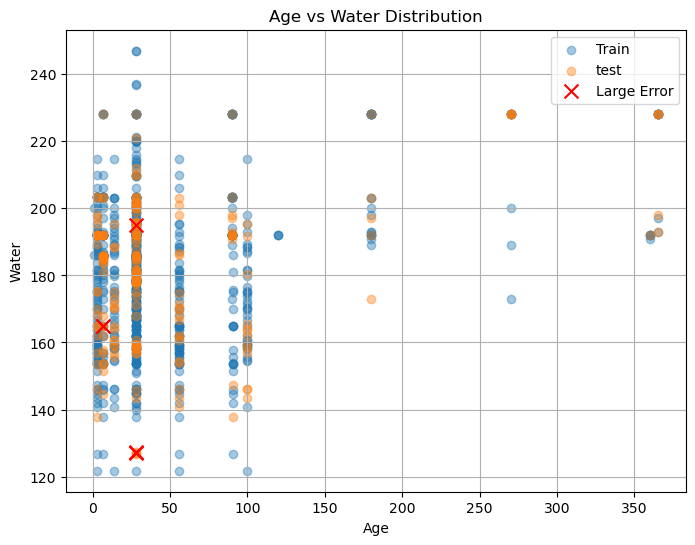

In [54]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train["Age"],
    X_train["Water"],
    alpha=0.4,
    label="Train"
)

plt.scatter(
    X_test["Age"],
    X_test["Water"],
    alpha=0.4,
    label="test"
)

plt.scatter(
    X_test.iloc[worst_idx]["Age"],
    X_test.iloc[worst_idx]["Water"],
    color="red",
    marker="x",
    s=100,
    label="Large Error"
)

plt.xlabel("Age")
plt.ylabel("Water")
plt.title("Age vs Water Distribution")
plt.legend()
plt.grid()
plt.show()